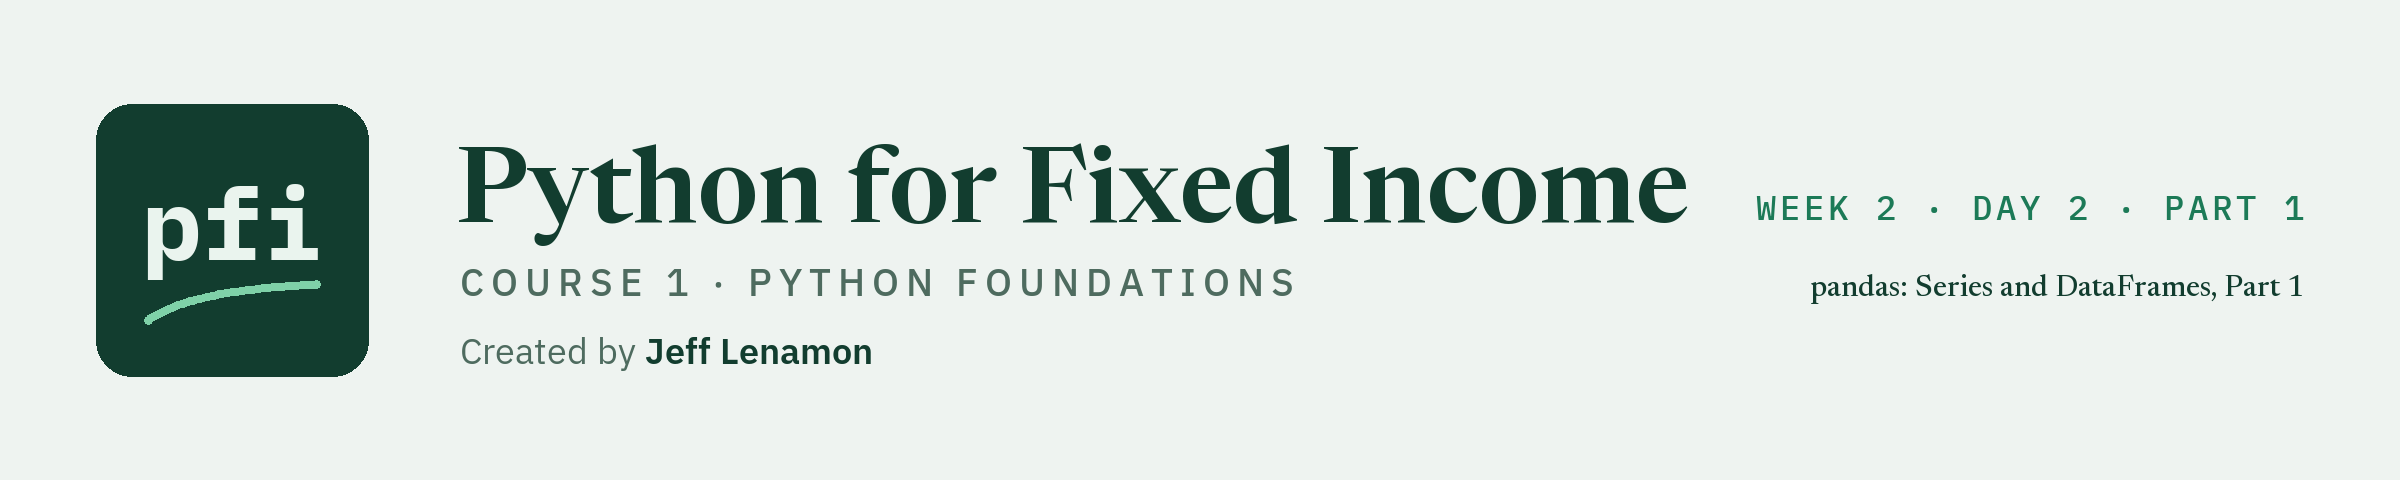

# pandas: Series and DataFrames, Part 1

Week 2, Day 2, Part 1. Holding a whole portfolio in one table, and pulling out the rows and columns a question needs.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week2/day2/07_pandas_series_and_dataframes.ipynb)

## Before You Start: Install the Libraries

Run this cell first.

It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab.

If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course01_python_foundations/requirements.txt
NEEDED = {
    "ipykernel": "ipykernel==7.4.0",
    "jinja2": "jinja2==3.1.6",
    "matplotlib": "matplotlib==3.11.2",
    "nbformat": "nbformat==5.11.1",
    "nltk": "nltk==3.10.3",
    "numpy": "numpy==2.5.3",
    "openpyxl": "openpyxl==3.1.5",
    "pandas": "pandas==3.0.6",
    "plotly": "plotly==7.1.0",
    "pytest": "pytest==9.1.1",
    "seaborn": "seaborn==0.13.2",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

11 packages checked, all present


The credit desk's portfolio has grown from four bonds to two hundred.

Each bond now comes with a CUSIP, an issuer name, a sector, a rating, a maturity date, a price, a spread, a duration, and a position size.

The tools so far do not fit that.

A list or a dictionary holds the data but answers no questions without a loop.

A NumPy array calculates on a whole column at once, but it holds one type of value and knows nothing about tickers or column names.

The desk needs a table: text and numbers side by side, every column with a name, every row a bond.

**pandas** is the Python library for that.

It has two structures.

A **Series** is one labelled column.

A **DataFrame** is a table of them.

We build both by hand from the four bonds of week 1, then load the full holdings file and work on that for the rest of the lesson.

The issuers are invented.

<table align="left">
<tr><th align="left">Ticker</th><th align="left">Coupon (%)</th><th align="left">Maturity</th><th align="left">Price</th><th align="left">Face held</th><th align="left">Rating</th></tr>
<tr><td align="left">QVNE</td><td align="left">5.25</td><td align="left">2033</td><td align="left">98.50</td><td align="left">1,500,000</td><td align="left">BBB</td></tr>
<tr><td align="left">DNMR</td><td align="left">6.125</td><td align="left">2034</td><td align="left">103.25</td><td align="left">500,000</td><td align="left">BB+</td></tr>
<tr><td align="left">PLWK</td><td align="left">4.75</td><td align="left">2031</td><td align="left">95.00</td><td align="left">750,000</td><td align="left">A-</td></tr>
<tr><td align="left">HLVF</td><td align="left">7.50</td><td align="left">2032</td><td align="left">101.00</td><td align="left">250,000</td><td align="left">B+</td></tr>
</table>
<br clear="left">

## 7.1 A Series: One Labelled Column

We imported pandas on Day 0 and built a table with it on Day 5 of week 1.

Now we learn it properly.

Q. Import pandas.

In [2]:
# the same import as on Day 0
import pandas as pd

Q. Put the four prices in a Series.

In [3]:
# the prices as a list, as in week 1
price_list = [98.5, 103.25, 95.0, 101.0]

# pd.Series() turns a list into a Series
prices = pd.Series(price_list)
print(prices)

0     98.50
1    103.25
2     95.00
3    101.00
dtype: float64


The four prices are in the right-hand column.

The left-hand column, 0 to 3, is the **index**: a label for each row.

We gave no labels, so pandas numbered the rows.

The last line, `dtype: float64`, is the type of the values, as in NumPy.

A row number says nothing about which bond a price belongs to.

The index can hold something more useful.

Q. Label each price with its ticker.

In [4]:
ticker_list = ['QVNE', 'DNMR', 'PLWK', 'HLVF']

# index= sets the label of each row
prices = pd.Series(price_list, index=ticker_list)
print(prices)

QVNE     98.50
DNMR    103.25
PLWK     95.00
HLVF    101.00
dtype: float64


Each price now sits next to its ticker.

In NumPy the tickers and the prices were two separate arrays that we had to keep in the same order ourselves.

In a Series the label travels with the value.

Q. What is inside a Series?

In [5]:
# to_numpy() returns the data as a NumPy array
print(prices.to_numpy())
print(type(prices.to_numpy()))
# index holds the labels
print(prices.index)

[ 98.5  103.25  95.   101.  ]
<class 'numpy.ndarray'>
Index(['QVNE', 'DNMR', 'PLWK', 'HLVF'], dtype='str')


The values are a NumPy array: square brackets, no commas, type `numpy.ndarray`.

A Series of numbers is a NumPy array with an index attached, so everything from the NumPy notebook about arithmetic on a whole column still applies.

The index holds the four tickers.

Its `dtype` is the type of the labels: `str`, the label for text that Day 5 of week 1 pointed out, or `object` in older versions of pandas.

Q. What is the price of PLWK? And what is the first price in the Series?

In [6]:
# square brackets with a label look up the value for that label
print('PLWK:', prices['PLWK'])
# iloc looks up by position, counting from 0
print('First price:', prices.iloc[0])

PLWK: 95.0
First price: 98.5


95.0 for PLWK and 98.5 for the first row, which is QVNE.

A label in square brackets works like a key in a dictionary.

`iloc` stands for 'integer location' and works like an index in a list.

`iloc` is followed by square brackets, not round ones, because it looks something up.

**Predict 1**

Many older tutorials look up a Series by a plain number.

Here the labels are tickers:

```
prices[0]
```

What do you expect?

> A) 98.5, the first price.
>
> B) An error.
>
> C) `QVNE`, the first label.

Decide, then run the cell.

In [7]:
# a plain number in square brackets, on a Series whose labels are tickers
prices[0]

KeyError: 0

The answer is B. A `KeyError: 0`.

The number 0 is not one of the labels, which are tickers.

Older versions of pandas quietly looked up by position instead, and printed a warning. pandas 3 refuses.

The rule: a label in square brackets looks up by label, and `iloc` looks up by position.

Keep the two apart and the code means the same thing in every version.

Q. Show the prices of PLWK and QVNE, in that order.

In [8]:
# a list of labels returns a smaller Series, in the order asked
print(prices[['PLWK', 'QVNE']])

PLWK    95.0
QVNE    98.5
dtype: float64


Q. Show the last two prices.

In [9]:
# iloc with a slice works by position: -2: is the last two
print(prices.iloc[-2:])

PLWK     95.0
HLVF    101.0
dtype: float64


PLWK and HLVF.

An `iloc` slice stops before its end, as every slice does.

`iloc` has a partner, `loc`, which looks up by label.

**Predict 2**

An `iloc` slice stops before its end.

Here is a `loc` slice that ends at the label PLWK:

```
print(prices.loc[:'PLWK'])
```

How many prices does it print?

> A) Two: QVNE and DNMR, because a slice stops before its end.
>
> B) Three: QVNE, DNMR, and PLWK.

Decide, then run the cell.

In [10]:
# loc with a slice works by label
print(prices.loc[:'PLWK'])

QVNE     98.50
DNMR    103.25
PLWK     95.00
dtype: float64


The answer is B: QVNE, DNMR, and PLWK.

The `loc` slice includes its end, because with labels there is no 'one past PLWK' to name.

Q. A colleague sends the prices of two bonds as a dictionary. Make a Series from it. Can an array be turned into a Series too?

In [11]:
# a dictionary becomes a Series: the keys are the index and the values are the data
price_by_ticker = pd.Series({'QVNE': 98.5, 'DNMR': 103.25})
print(price_by_ticker)
print()
# an array becomes a Series with the default numbering
print(pd.Series(prices.to_numpy()))

QVNE     98.50
DNMR    103.25
dtype: float64

0     98.50
1    103.25
2     95.00
3    101.00
dtype: float64


The dictionary gave a Series with the tickers as the index.

The array gave one with the numbers 0 to 3, because an array carries no labels.

Q. How much coupon does each position pay in a year? The coupon is in percent of face.

In [12]:
# two more Series with the same labels
coupons = pd.Series([5.25, 6.125, 4.75, 7.5], index=ticker_list)
faces = pd.Series([1500000, 500000, 750000, 250000], index=ticker_list)

# arithmetic applies to every row, as with arrays
incomes = faces * coupons / 100
print(incomes)

# the array methods from the NumPy notebook work on a Series
print('Total annual coupon income:', incomes.sum())

QVNE    78750.0
DNMR    30625.0
PLWK    35625.0
HLVF    18750.0
dtype: float64
Total annual coupon income: 163750.0


78,750 for QVNE, then 30,625, 35,625, and 18,750: the same figures as in the NumPy notebook, now with a ticker beside each one.

The total is 163,750, which matches week 1.

`sum()`, `mean()`, `min()`, and `max()` work on a Series as they do on an array.

There is one thing a Series does that an array cannot.

Suppose the face amounts arrive from another system in a different order.

Q. Work out the coupon income again, with the face amounts listed from the smallest position to the largest.

In [13]:
# the same four face amounts, in a different order
faces_by_size = pd.Series([250000, 500000, 750000, 1500000],
                          index=['HLVF', 'DNMR', 'PLWK', 'QVNE'])

# pandas matches the rows by label, not by position
print(faces_by_size * coupons / 100)

DNMR    30625.0
HLVF    18750.0
PLWK    35625.0
QVNE    78750.0
dtype: float64


The four incomes are the same as before: 78,750 for QVNE, 30,625 for DNMR, 35,625 for PLWK, and 18,750 for HLVF.

The rows print in alphabetical order because pandas sorts the labels when the two indexes are not in the same order.

pandas lined the two Series up by ticker before multiplying.

Two NumPy arrays in different orders would have been multiplied position by position, with no error and four wrong numbers.

Matching by label has a cost of its own.

It does not check that every label was found.

Q. The face amounts from the other system arrive without HLVF. What happens to its income, and to the total?

In [14]:
# drop() returns the Series without that label, so the HLVF row is left out
faces_missing = faces_by_size.drop('HLVF')

# HLVF has a coupon and no face, so there is nothing to multiply
incomes_missing = faces_missing * coupons / 100
print(incomes_missing)
print('Total annual coupon income:', incomes_missing.sum())

DNMR    30625.0
HLVF        NaN
PLWK    35625.0
QVNE    78750.0
dtype: float64
Total annual coupon income: 145000.0


HLVF comes back as `NaN`, which stands for 'not a number' and is how pandas marks a missing value.

`sum()` skips the gap.

The total is 145,000 instead of 163,750, short by the 18,750 of HLVF, and there is no error.

After arithmetic on two Series from different sources, look for `NaN` in the result before trusting a total.

**Excel side by side.** A Series is a single column of a worksheet with a label on every row, close to a named range with the tickers in the column beside it.

Multiplying two Series is a formula filled down.

The matching by label is what a `VLOOKUP` on the ticker does before the multiplication, and pandas does it without being asked.

When a ticker is not found, `VLOOKUP` shows `#N/A` and a `=SUM()` over that column shows `#N/A` as well. pandas shows `NaN` and still returns a total.

## 7.2 A DataFrame: A Table of Columns

A DataFrame is a set of Series that share one index: a table.

At the end of week 1 we built one from a dictionary of lists.

Q. Put the four bonds in a DataFrame.

In [15]:
# each key is a column name and each list is a column
desk = pd.DataFrame({
    'Ticker': ['QVNE', 'DNMR', 'PLWK', 'HLVF'],
    'Coupon': [5.25, 6.125, 4.75, 7.5],
    'Maturity': [2033, 2034, 2031, 2032],
    'Price': [98.5, 103.25, 95.0, 101.0],
    'Face': [1500000, 500000, 750000, 250000],
    'Rating': ['BBB', 'BB+', 'A-', 'B+'],
})

# show the table
desk

,Ticker,Coupon,Maturity,Price,Face,Rating
0,QVNE,5.250,2033,98.50,1500000,BBB
1,DNMR,6.125,2034,103.25,500000,BB+
2,PLWK,4.750,2031,95.00,750000,A-
3,HLVF,7.500,2032,101.00,250000,B+


Four rows and six columns, with text and numbers side by side.

That is what an array could not hold.

The numbers 0 to 3 down the left are the index.

As with the first Series, pandas numbered the rows because we gave no labels.

Q. What are the column names and the row labels of the table?

In [16]:
# columns holds the column names
print(desk.columns)
# index holds the row labels
print(desk.index)

Index(['Ticker', 'Coupon', 'Maturity', 'Price', 'Face', 'Rating'], dtype='str')
RangeIndex(start=0, stop=4, step=1)


The six column names, in the order of the dictionary.

`RangeIndex(start=0, stop=4, step=1)` is the default numbering: 0, 1, 2, 3.

Like `range()`, it stops before 4.

Q. What type of value does each column hold, and how many rows and columns does the table have?

In [17]:
# dtypes lists the type of every column
print(desk.dtypes)
# shape is (rows, columns)
print(desk.shape)

Ticker          str
Coupon      float64
Maturity      int64
Price       float64
Face          int64
Rating          str
dtype: object
(4, 6)


Coupon and Price are `float64`.

Maturity and Face are `int64`.

Ticker and Rating are text.

Each column has one type, like an array.

The table as a whole can mix them.

The shape is (4, 6): four bonds, six attributes.

Rows come first, as in a 2-D array.

Q. Pull the Price column out of the table. What type is it?

In [18]:
# square brackets with a column name select that column
desk_prices = desk['Price']
print(desk_prices)
print(type(desk_prices))

0     98.50
1    103.25
2     95.00
3    101.00
Name: Price, dtype: float64
<class 'pandas.Series'>


The four prices, with the row index on the left and the column name on the last line.

The type is `Series`.

This is the link between the two structures.

Every column of a DataFrame is a Series, so everything in section 7.1 works on a column of a table.

**Excel side by side.** A DataFrame is a worksheet with a header row.

The column names are the headers, the index is the row numbers down the left edge, and `desk['Price']` is the Price column selected by its header.

Square brackets with a name select a column.

Square brackets with a slice select rows.

Q. Show the first two bonds.

In [19]:
# a slice in square brackets selects rows by position, and stops before the end
print(desk[:2])

  Ticker  Coupon  Maturity   Price     Face Rating
0   QVNE   5.250      2033   98.50  1500000    BBB
1   DNMR   6.125      2034  103.25   500000    BB+


A slice can take a third number, the step.

Nothing before the first colon means 'from the top', and nothing before the second means 'to the end'.

Q. Show every second bond, then the bonds in reverse order.

In [20]:
# a step of 2 takes every second row
print(desk[::2])
print()
# a step of -1 walks backwards from the last row
print(desk[::-1])

  Ticker  Coupon  Maturity  Price     Face Rating
0   QVNE    5.25      2033   98.5  1500000    BBB
2   PLWK    4.75      2031   95.0   750000     A-

  Ticker  Coupon  Maturity   Price     Face Rating
3   HLVF   7.500      2032  101.00   250000     B+
2   PLWK   4.750      2031   95.00   750000     A-
1   DNMR   6.125      2034  103.25   500000    BB+
0   QVNE   5.250      2033   98.50  1500000    BBB


Rows 0 and 2 (QVNE and PLWK), then all four from HLVF back to QVNE.

The index numbers travel with their rows, so the reversed table still labels QVNE as 0.

A name or a list of names in the brackets picks columns.

A slice picks rows.

Q. The coupons and faces from section 7.1 are two Series with the same tickers as labels. Put them side by side in one table.

In [21]:
# a dictionary of Series: each key is a column name and each Series is a column
book = pd.DataFrame({'Coupon': coupons, 'Face': faces})
print(book)

      Coupon     Face
QVNE   5.250  1500000
DNMR   6.125   500000
PLWK   4.750   750000
HLVF   7.500   250000


The tickers became the index of the table, because both Series carry them.

The Series are matched by label, as in section 7.1, so the rows line up even if the order differed.

Q. The risk system sends each bond as a row, not as a column. Build the table from a list of rows.

In [22]:
# a list of rows: each inner list is one bond, in the order of the column names
rows = [['QVNE', 5.25, 98.5],
        ['DNMR', 6.125, 103.25]]

# columns= names the columns
risk = pd.DataFrame(rows, columns=['Ticker', 'Coupon', 'Price'])
print(risk)

  Ticker  Coupon   Price
0   QVNE   5.250   98.50
1   DNMR   6.125  103.25


A list of lists is a list of rows, and `columns=` supplies the names.

The dictionary form earlier built the table column by column.

This form builds it row by row.

Q. To test code before real data arrives, make up a table: five bonds, two days of changes in yield in basis points, with an average of 0 and a typical size of 5.

In [23]:
import numpy as np

# the random number generator from the NumPy notebook, with its seed
rng = np.random.default_rng(42)

# a 5 by 2 array of made-up changes becomes a table with named columns
made_up = pd.DataFrame(rng.standard_normal((5, 2)) * 5, columns=['Day 1', 'Day 2'])
print(made_up.round(2))

   Day 1  Day 2
0   1.52  -5.20
1   3.75   4.70
2  -9.76  -6.51
3   0.64  -1.58
4  -0.08  -4.27


Five rows and two columns of made-up changes.

Any NumPy array of two dimensions can become a table this way.

The same seed gives the same numbers on every run.

## 7.3 The Holdings File

Nobody types two hundred bonds into a dictionary.

The desk's holdings arrive as a CSV file, `holdings.csv`, in the `data` folder of the course repo.

Q. Load the holdings file into a DataFrame.

In [24]:
import os

# on your own machine the file is in the repo's data folder. In Colab it is read from GitHub.
if os.path.exists('../../../data/holdings.csv'):
    data_path = '../../../data/holdings.csv'
else:
    data_path = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/holdings.csv'

holdings = pd.read_csv(data_path)

`pd.read_csv()` reads a CSV file and returns a DataFrame.

The first line of the file becomes the column names.

The `if` picks where to read from.

On your own machine the file is three folders up from this notebook: `..` is `week2`, `../..` is `course01_python_foundations`, and `../../..` is the top folder of the repo, which holds `data`.

In Colab that folder does not exist, so pandas reads the same file from the course's GitHub page.

**Excel side by side.** `pd.read_csv()` is double-clicking the CSV file, or Data, From Text/CSV.

Q. What do the first rows look like?

In [25]:
# the first rows, as on Day 5 of week 1
holdings.head()

,as_of_date,cusip,ticker,issuer,sector,rating,coupon,maturity,price,price_date,accrued,yield_pct,oas,duration,spread_duration,dts,amount_outstanding,par_held,market_value
0,2026-09-30,99080CAE8,BEZE,Bezane Finance,Financials,BBB-,7.000,2032-06-18,106.727,2026-09-30,1.983,5.606,147,4.627,4.627,680.2,1650000000,5000000,5435500.0
1,2026-09-30,99049XAE2,BEZH,Bezamyth Machinery,Industrials,B,8.125,2029-04-17,97.556,2026-09-30,3.679,9.220,535,2.165,2.165,1158.3,950000000,250000,253087.5
2,2026-09-30,99039NAC0,BEZL,Bezoquil Freight,Transportation,BB,5.125,2030-06-03,98.730,2026-09-30,1.666,5.509,153,3.250,3.250,497.2,850000000,1500000,1505940.0
3,2026-09-30,99039NAG1,BEZL,Bezoquil Freight,Transportation,BB,6.125,2053-04-09,92.261,2026-09-30,2.909,6.756,218,12.113,12.113,2640.6,2200000000,500000,475850.0
4,2026-09-30,99034IAD4,BEZN,Bezorin Finance,Financials,BBB-,4.625,2036-04-05,92.883,2026-09-30,2.248,5.600,127,7.338,7.338,931.9,1100000000,2500000,2378275.0


One row per bond.

The table is wide, so scroll to the right to see every column.

The third and fourth rows share an issuer: BEZL has two bonds with different coupons and maturities.

Each bond has its own CUSIP.

Q. And the last rows?

In [26]:
# the last 3 rows
holdings.tail(3)

,as_of_date,cusip,ticker,issuer,sector,rating,coupon,maturity,price,price_date,accrued,yield_pct,oas,duration,spread_duration,dts,amount_outstanding,par_held,market_value
197,2026-09-30,99062KAA0,ZEPL,Zephizal Medical,Health Care,A-,4.125,2036-11-12,90.863,2026-09-30,1.581,5.303,95,7.919,7.919,752.3,1450000000,1250000,1155550.0
198,2026-09-30,99138IAD9,ZEPN,Zephiskan Resources,Energy,A-,7.250,2031-09-13,110.669,2026-09-30,0.342,4.803,72,4.177,4.177,300.7,2250000000,750000,832582.5
199,2026-09-30,99138IAF4,ZEPN,Zephiskan Resources,Energy,A-,5.000,2036-08-16,93.656,2026-09-30,0.611,5.854,151,7.565,7.565,1142.3,350000000,2500000,2356675.0


The index of the last row is 199.

Counting starts at 0, so that makes 200 rows.

Q. How large is the table?

In [27]:
print(holdings.shape)

(200, 19)


(200, 19): 200 bonds, 19 columns.

Q. What are the columns?

In [28]:
holdings.columns

Index(['as_of_date', 'cusip', 'ticker', 'issuer', 'sector', 'rating', 'coupon',
       'maturity', 'price', 'price_date', 'accrued', 'yield_pct', 'oas',
       'duration', 'spread_duration', 'dts', 'amount_outstanding', 'par_held',
       'market_value'],
      dtype='str')

Nineteen names, all lower case with underscores in place of spaces.

Here is what each column holds.

Every bond is a fixed-rate bullet bond that pays semiannual coupons on a 30/360 day count.

<table align="left">
<tr><th align="left">Column</th><th align="left">Meaning</th><th align="left">Units</th></tr>
<tr><td align="left"><code>as_of_date</code></td><td align="left">Date of the holdings report</td><td align="left">date as text</td></tr>
<tr><td align="left"><code>cusip</code></td><td align="left">Identifier of the bond, invented</td><td align="left">text</td></tr>
<tr><td align="left"><code>ticker</code></td><td align="left">Short code of the issuer</td><td align="left">text</td></tr>
<tr><td align="left"><code>issuer</code></td><td align="left">Name of the issuer, invented</td><td align="left">text</td></tr>
<tr><td align="left"><code>sector</code></td><td align="left">Sector of the issuer</td><td align="left">text</td></tr>
<tr><td align="left"><code>rating</code></td><td align="left">Credit rating of the bond</td><td align="left">text</td></tr>
<tr><td align="left"><code>coupon</code></td><td align="left">Annual coupon</td><td align="left">percent of face</td></tr>
<tr><td align="left"><code>maturity</code></td><td align="left">Maturity date</td><td align="left">date as text</td></tr>
<tr><td align="left"><code>price</code></td><td align="left">Clean price</td><td align="left">per 100 of face</td></tr>
<tr><td align="left"><code>price_date</code></td><td align="left">Date of the price</td><td align="left">date as text</td></tr>
<tr><td align="left"><code>accrued</code></td><td align="left">Accrued interest</td><td align="left">per 100 of face</td></tr>
<tr><td align="left"><code>yield_pct</code></td><td align="left">Yield to maturity</td><td align="left">percent</td></tr>
<tr><td align="left"><code>oas</code></td><td align="left">Option-adjusted spread</td><td align="left">basis points</td></tr>
<tr><td align="left"><code>duration</code></td><td align="left">Modified duration</td><td align="left">years</td></tr>
<tr><td align="left"><code>spread_duration</code></td><td align="left">Spread duration</td><td align="left">years</td></tr>
<tr><td align="left"><code>dts</code></td><td align="left">Duration times spread: <code>spread_duration</code> times <code>oas</code></td><td align="left">years times basis points</td></tr>
<tr><td align="left"><code>amount_outstanding</code></td><td align="left">Size of the whole bond issue</td><td align="left">dollars of face</td></tr>
<tr><td align="left"><code>par_held</code></td><td align="left">Face amount the desk holds</td><td align="left">dollars of face</td></tr>
<tr><td align="left"><code>market_value</code></td><td align="left"><code>par_held</code> times (<code>price</code> plus <code>accrued</code>), divided by 100</td><td align="left">dollars</td></tr>
</table>
<br clear="left">

Q. What type is each column, and is anything missing?

In [29]:
# the same first look as on Day 5 of week 1
holdings.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   as_of_date          200 non-null    str    
 1   cusip               200 non-null    str    
 2   ticker              200 non-null    str    
 3   issuer              200 non-null    str    
 4   sector              200 non-null    str    
 5   rating              200 non-null    str    
 6   coupon              200 non-null    float64
 7   maturity            200 non-null    str    
 8   price               200 non-null    float64
 9   price_date          200 non-null    str    
 10  accrued             200 non-null    float64
 11  yield_pct           200 non-null    float64
 12  oas                 200 non-null    int64  
 13  duration            200 non-null    float64
 14  spread_duration     200 non-null    float64
 15  dts                 200 non-null    float64
 16  amount_outstanding 

Every column has 200 non-null values, so nothing is missing.

Eight columns are text, eight are `float64`, and three are `int64`.

The three date columns are held as text.

## 7.4 Selecting Columns

Most questions need two or three of the nineteen columns.

Selecting them is the first skill.

Q. Show the spread of the first five bonds.

In [30]:
# one column name in square brackets returns that column as a Series
holdings['oas'].head()

0    147
1    535
2    153
3    218
4    127
Name: oas, dtype: int64

147, 535, 153, 218, and 127 basis points.

`head()` works on a Series as it does on a table.

**Predict 3**

On a desk the spread is written OAS, in capitals.

The column in the file is `oas`:

```
holdings['OAS']
```

What do you expect?

> A) The spreads, because pandas ignores capitals in a column name.
>
> B) An error.
>
> C) An empty column.

Decide, then run the cell.

In [31]:
# the column is named oas, in lower case
holdings['OAS']

KeyError: 'OAS'

The answer is B. A `KeyError: 'OAS'`.

The traceback is long because the error passes through several layers of pandas.

Go straight to the last line: it names the key that could not be found.

This is the same error a dictionary gives for a missing key.

Column names are case-sensitive, so `'OAS'` and `'oas'` are different names.

When you see a `KeyError`, compare your spelling with `holdings.columns`.

Q. Show the ticker, coupon, maturity, and price of the first five bonds.

In [32]:
# a list of column names inside the square brackets returns a smaller table
holdings[['ticker', 'coupon', 'maturity', 'price']].head()

,ticker,coupon,maturity,price
0,BEZE,7.000,2032-06-18,106.727
1,BEZH,8.125,2029-04-17,97.556
2,BEZL,5.125,2030-06-03,98.730
3,BEZL,6.125,2053-04-09,92.261
4,BEZN,4.625,2036-04-05,92.883


Four columns, in the order we asked for them.

Note the double square brackets.

The outer pair is the selection and the inner pair is a list of names.

One name gives a Series.

A list of names gives a DataFrame, even when the list has one name in it.

Q. Summarize the coupon, price, yield, spread, and duration columns.

In [33]:
# describe(), from Day 5 of week 1, on five columns
holdings[['coupon', 'price', 'yield_pct', 'oas', 'duration']].describe()

,coupon,price,yield_pct,oas,duration
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,5.937500,98.828295,6.087815,185.750000,6.470405
std,1.648435,7.404931,1.957543,193.949632,3.350506
min,3.250000,62.045000,4.089000,19.000000,0.927000
25%,4.750000,95.140000,5.058750,81.750000,3.880250
50%,5.687500,99.416000,5.547000,135.500000,6.306500
75%,6.875000,103.004000,6.394500,213.000000,8.139750
max,11.000000,119.131000,19.304000,1551.000000,16.042000


**Observations**

* Coupons run from 3.25 to 11 percent, with a mean of 5.9375.
* Prices run from 62.045 to 119.131. The median, in the 50% row, is 99.416, so more than half of the bonds are priced below par.
* The spread column is lopsided: the median OAS is 135.5 basis points and the mean is 185.75, with a maximum of 1,551.
* A few very wide bonds pull the mean above the median.
* Durations run from 0.927 to 16.042 years, with a mean of about 6.47.
* The `25%` and `75%` rows are the quartiles: a quarter of the bonds sit below the first and a quarter above the second.
* The `std` row is the sample standard deviation, the `ddof=1` version from the NumPy notebook. pandas uses that version unless told otherwise.

**Excel side by side.** Selecting columns is hiding the columns you do not need, or copying a few of them to a new sheet.

`describe()` has no single Excel function.

It is `COUNT`, `AVERAGE`, `STDEV.S`, `MIN`, `QUARTILE.INC`, and `MAX` on every column at once.

## 7.5 Rows by Position and by Label

A column is selected by name.

A row can be selected two ways, with the two tools from section 7.1: by its position in the table, with `iloc`, or by its label in the index, with `loc`.

Q. Show the first bond in the table.

In [34]:
# iloc[0] is the row at position 0
holdings.iloc[0]

as_of_date                2026-09-30
cusip                      99080CAE8
ticker                          BEZE
issuer                Bezane Finance
sector                    Financials
rating                          BBB-
coupon                           7.0
maturity                  2032-06-18
price                        106.727
price_date                2026-09-30
accrued                        1.983
yield_pct                      5.606
oas                              147
duration                       4.627
spread_duration                4.627
dts                            680.2
amount_outstanding        1650000000
par_held                     5000000
market_value               5435500.0
Name: 0, dtype: object

One row comes back as a Series, turned on its side: the column names are now the labels.

The first bond is BEZE, a 7% bond of 2032 rated BBB-.

The last line says `dtype: object`.

A row mixes text and numbers, and `object` is the type pandas uses for a mix.

Q. Show the first three bonds, and only the first four columns.

In [35]:
# iloc[rows, columns], both by position. A slice stops before its end.
holdings.iloc[0:3, 0:4]

,as_of_date,cusip,ticker,issuer
0,2026-09-30,99080CAE8,BEZE,Bezane Finance
1,2026-09-30,99049XAE2,BEZH,Bezamyth Machinery
2,2026-09-30,99039NAC0,BEZL,Bezoquil Freight


Rows 0, 1, and 2, and columns 0 to 3.

As with lists and arrays, the end of the slice is left out.

`iloc` takes positions only.

It is the way to say 'the first three rows' or 'the last row' (`iloc[-1]`), whatever the table holds.

Positions are fragile.

Sort the table or remove a bond, and position 0 is a different bond.

A label stays with its row.

The best label for a bond is its CUSIP, because no two bonds share one.

Q. Make the CUSIP the index of the table.

In [36]:
# set_index() returns a new table with that column as the row labels
by_cusip = holdings.set_index('cusip')
by_cusip[['ticker', 'coupon', 'maturity', 'price']].head(3)

,ticker,coupon,maturity,price
cusip,,,,
99080CAE8,BEZE,7.000,2032-06-18,106.727
99049XAE2,BEZH,8.125,2029-04-17,97.556
99039NAC0,BEZL,5.125,2030-06-03,98.730


The CUSIPs have moved to the left edge, in bold, in place of the numbers 0, 1, 2.

`set_index()` did not change `holdings`.

It returned a new table, which we stored as `by_cusip`.

Most pandas methods work this way: they hand back a new table and leave the original alone.

The ticker would be a poor index here, because one issuer can have several bonds, as BEZL showed in the first rows.

Q. Show the bond with CUSIP 99039NAC0.

In [37]:
# loc looks a row up by its label
by_cusip.loc['99039NAC0']

as_of_date                  2026-09-30
ticker                            BEZL
issuer                Bezoquil Freight
sector                  Transportation
rating                              BB
coupon                           5.125
maturity                    2030-06-03
price                            98.73
price_date                  2026-09-30
accrued                          1.666
yield_pct                        5.509
oas                                153
duration                          3.25
spread_duration                   3.25
dts                              497.2
amount_outstanding           850000000
par_held                       1500000
market_value                 1505940.0
Name: 99039NAC0, dtype: object

BEZL 5.125% of 2030, rated BB, priced at 98.73 with an OAS of 153.

We did not need to know where in the table the bond sits.

Q. What is the price of that bond?

In [38]:
# loc[row label, column name] returns a single value
print(by_cusip.loc['99039NAC0', 'price'])

98.73


The price is 98.73.

The row label comes first and the column name second.

Q. Show the ticker and price of two bonds at once: BEZE and BEZL. First by label, then by position.

In [39]:
# lists of row labels and of column names return a smaller table
print(by_cusip.loc[['99080CAE8', '99039NAC0'], ['ticker', 'price']])
print()
# the same two bonds by position: rows 0 and 2, columns 2 and 8
print(holdings.iloc[[0, 2], [2, 8]])

          ticker    price
cusip                    
99080CAE8   BEZE  106.727
99039NAC0   BEZL   98.730

  ticker    price
0   BEZE  106.727
2   BEZL   98.730


The same two bonds and the same two columns both times: BEZE at 106.727 and BEZL at 98.73.

The lists make the answer a table.

`loc` takes names and `iloc` takes numbers.

**Predict 4**

What if the two are mixed up?

Here `iloc` is given column names:

```
holdings.iloc[[0, 2], ['ticker', 'price']]
```

What do you expect?

> A) The same small table, because pandas works out what was meant.
>
> B) An error.

Decide, then run the cell.

In [40]:
# column names given to iloc
holdings.iloc[[0, 2], ['ticker', 'price']]

IndexError: .iloc requires numeric indexers, got ['ticker' 'price']

The answer is B. An `IndexError`: `.iloc requires numeric indexers`, and it echoes the names it was given.

The rule is short: `loc` is by label and `iloc` is by integer position.

Slices work on rows of a table as they did on a Series.

Q. Show the first three bonds twice: once by position, and once by label, from 99080CAE8 to 99039NAC0.

In [41]:
# by position: stops before position 3
print(by_cusip.iloc[0:3]['ticker'])
print()
# by label: includes the end label
print(by_cusip.loc['99080CAE8':'99039NAC0']['ticker'])

cusip
99080CAE8    BEZE
99049XAE2    BEZH
99039NAC0    BEZL
Name: ticker, dtype: str

cusip
99080CAE8    BEZE
99049XAE2    BEZH
99039NAC0    BEZL
Name: ticker, dtype: str


The same three bonds both times: BEZE, BEZH, and BEZL.

The `iloc` slice left out position 3, and the `loc` slice kept its end label, as in section 7.1.

What happens when the label is not in the index?

Here the last character of the CUSIP is mistyped.

In [42]:
# the real CUSIP ends in 8
by_cusip.loc['99080CAE9']

KeyError: '99080CAE9'

A `KeyError: '99080CAE9'`.

Again the last line of the traceback names the label that was not found.

pandas does not guess the nearest match.

One wrong character and the lookup fails, which is what we want from a lookup of a security.

**Excel side by side.**

<table align="left">
<tr><th align="left">Question</th><th align="left">pandas</th><th align="left">Excel</th></tr>
<tr><td align="left">The third row</td><td align="left"><code>holdings.iloc[2]</code></td><td align="left">row 4 of the sheet, under the header</td></tr>
<tr><td align="left">Price of a CUSIP</td><td align="left"><code>by_cusip.loc['99039NAC0', 'price']</code></td><td align="left"><code>=VLOOKUP("99039NAC0", B:I, 8, FALSE)</code></td></tr>
<tr><td align="left">The same, without counting columns</td><td align="left"><code>by_cusip.loc['99039NAC0', 'price']</code></td><td align="left"><code>=INDEX(I:I, MATCH("99039NAC0", B:B, 0))</code></td></tr>
<tr><td align="left">A CUSIP that is not there</td><td align="left"><code>KeyError</code></td><td align="left"><code>#N/A</code></td></tr>
</table>
<br clear="left">

The Excel formulas assume the CUSIP in column B and the price in column I, as in `holdings.csv`.

`loc` is `INDEX` and `MATCH` in one step, and it uses the column's name where `VLOOKUP` needs its number.

## You Can Now

By the end of this notebook, you can:

* Build a Series and a DataFrame by hand, from lists, a dictionary of Series, rows, or random numbers
* Say what an index is, and why pandas lines two Series up by label before it multiplies
* Look for `NaN` after arithmetic on two Series from different sources
* Load a holdings file into a table and take a first look: its size, its columns, their types, and whether anything is missing
* Pull out the columns a question needs
* Look a bond up by its CUSIP with `loc`, and pick rows and columns by position with `iloc`

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

The exercises use the second desk's three bonds and the 200-bond holdings file, with questions the lesson did not ask.

The issuers are invented.

<table align="left">
<tr><th align="left">Ticker</th><th align="left">Coupon (%)</th><th align="left">Price</th><th align="left">Face held</th></tr>
<tr><td align="left">TRNW</td><td align="left">4.375</td><td align="left">96.25</td><td align="left">2,000,000</td></tr>
<tr><td align="left">OSMC</td><td align="left">5.00</td><td align="left">100.00</td><td align="left">1,250,000</td></tr>
<tr><td align="left">CLDB</td><td align="left">8.25</td><td align="left">104.50</td><td align="left">500,000</td></tr>
</table>
<br clear="left">

Replace each `...` with your own code, then run the check cell under it.

Run the next cell first.

It imports pandas, loads a fresh copy of the holdings as it is in the file, and defines `check`, a small function that marks your answers.

It allows for tiny rounding differences in numbers with a decimal point.

In [43]:
import os

import pandas as pd


def check(label, answer, expected):
    """Compare an exercise answer to the expected value and print the result."""
    if answer is ... or answer is None:
        print(label + ': not attempted yet')
        return
    if getattr(answer, 'ndim', 0) > 0 and not isinstance(expected, list):
        # a whole column or table was stored where a single value is expected
        print(label + ': not yet. A single value is expected, and you have a column or a table.')
        return
    if isinstance(expected, list):
        # a list of values: the same values in the same order
        correct = list(answer) == expected
    elif isinstance(expected, float):
        # single numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 0.000001
    else:
        correct = answer == expected
    if correct:
        print(label + ': correct')
    else:
        print(label + ': not yet. You have', answer)


# a fresh copy of the holdings. In Colab it is read from GitHub.
if os.path.exists('../../../data/holdings.csv'):
    data_path = '../../../data/holdings.csv'
else:
    data_path = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/holdings.csv'

holdings = pd.read_csv(data_path)
print(holdings.shape)

(200, 19)


### Exercise 1

Q. Put the prices, the coupons, and the face amounts of the second desk in three Series, each labelled with the tickers. Look up the price of OSMC by its label and store it in **ex1_osmc_price**. Look up the last price by its position and store it in **ex1_last_price**. Then find the total annual coupon income and store it in **ex1_income**.

In [44]:
ex1_osmc_price = ...
ex1_last_price = ...
ex1_income = ...

In [45]:
check('Exercise 1 OSMC price', ex1_osmc_price, 100.0)
check('Exercise 1 last price', ex1_last_price, 104.5)
check('Exercise 1 income', ex1_income, 191250.0)

Exercise 1 OSMC price: not attempted yet
Exercise 1 last price: not attempted yet
Exercise 1 income: not attempted yet


### Exercise 2

Q. Put the second desk in a DataFrame named **ex2_desk**, with the columns `Ticker`, `Coupon`, `Price`, and `Face`. Store its number of rows in **ex2_rows** and its number of columns in **ex2_columns**. Then pull out the `Price` column and store its average in **ex2_avg_price**.

In [46]:
ex2_desk = ...
ex2_rows = ...
ex2_columns = ...
ex2_avg_price = ...

In [47]:
check('Exercise 2 rows', ex2_rows, 3)
check('Exercise 2 columns', ex2_columns, 4)
check('Exercise 2 average price', ex2_avg_price, 100.25)

Exercise 2 rows: not attempted yet
Exercise 2 columns: not attempted yet
Exercise 2 average price: not attempted yet


### Exercise 3

Q. From the holdings, keep only the `ticker`, `sector`, `rating`, and `oas` columns, in a table named **ex3_table**. Store its number of columns in **ex3_columns**. Then find the highest yield in the file and the lowest coupon, and store them in **ex3_max_yield** and **ex3_min_coupon**.

In [48]:
ex3_table = ...
ex3_columns = ...
ex3_max_yield = ...
ex3_min_coupon = ...

In [49]:
check('Exercise 3 columns', ex3_columns, 4)
check('Exercise 3 highest yield', ex3_max_yield, 19.304)
check('Exercise 3 lowest coupon', ex3_min_coupon, 3.25)

Exercise 3 columns: not attempted yet
Exercise 3 highest yield: not attempted yet
Exercise 3 lowest coupon: not attempted yet


### Exercise 4

Q. Make a table indexed by CUSIP and use `loc` to look up the price and the rating of the bond with CUSIP 99071TAG7. Store them in **ex4_price** and **ex4_rating**. Then use `iloc` on the holdings to find the ticker of the last bond in the file, and store it in **ex4_last_ticker**.

In [50]:
ex4_price = ...
ex4_rating = ...
ex4_last_ticker = ...

In [51]:
check('Exercise 4 price', ex4_price, 97.612)
check('Exercise 4 rating', ex4_rating, 'A-')
check('Exercise 4 last ticker', ex4_last_ticker, 'ZEPN')

Exercise 4 price: not attempted yet
Exercise 4 rating: not attempted yet
Exercise 4 last ticker: not attempted yet


### Exercise 5: AI check

The second desk's face amounts arrive from another system, listed from the smallest position to the largest.

You ask an AI assistant for the total annual coupon income.

It gives you the code below.

It was written for this course in the style of an AI answer, and it has one bug.

Q. Read the code before you run it. What number do you expect? You worked out the income yourself in Exercise 1. Then run the code. Does it agree with you?

In [52]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
ai_coupons = pd.Series([4.375, 5.0, 8.25], index=['TRNW', 'OSMC', 'CLDB'])
ai_faces = pd.Series([500000, 1250000, 2000000], index=['CLDB', 'OSMC', 'TRNW'])

# the income of each position, then the total
ex5_income = (ai_faces.to_numpy() * ai_coupons / 100).sum()
print(f'Total annual coupon income: {ex5_income:,.0f}')

Total annual coupon income: 249,375


Q. Find the bug and fix the code in the cell above, so that **ex5_income** holds the right answer.

In [53]:
check('Exercise 5 income', ex5_income, 191250.0)

Exercise 5 income: not yet. You have 249375.0


## Congratulations!

You made it through the first half of pandas.

This morning the desk had four bonds typed in by hand.

Now you can load two hundred from a file, see what is in them, and find any one by its CUSIP.

You also met the idea that sets pandas apart from an array: a label travels with its value, so two columns line up by ticker however they arrive.

Next is pandas: Series and DataFrames, Part 2.

The table starts answering questions: you summarize it, filter it, rank it, add to it, and show it well.